In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import seaborn as sns
from matplotlib.ticker import MaxNLocator
import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",   # Prefer if installed
        "Liberation Serif",  # Common on Ubuntu / Debian
        "Nimbus Roman",      # Common with TeX / Ghostscript
        "DejaVu Serif"       # Matplotlib fallback
    ],
    "mathtext.fontset": "stix",       # Math symbols closer to Times
    "axes.unicode_minus": False,
})

import os
import sys
from pathlib import Path

# Utils lives under SynEnergy/. This notebook is Analysis/Figure/Motivation/
# Prefer the notebook file path (Cursor/VS Code); fall back to cwd.
_nb_file = globals().get("__vsc_ipynb_file__")
_nb_dir = Path(_nb_file).resolve().parent if _nb_file else Path.cwd().resolve()
synenergy_root = (_nb_dir / ".." / ".." / ".." / "SynEnergy").resolve()
if not (synenergy_root / "Utils").is_dir():
    # cwd may already be SysEnergy (or another parent)
    synenergy_root = None
    for p in [_nb_dir, *_nb_dir.parents]:
        cand = p / "SynEnergy"
        if (cand / "Utils").is_dir():
            synenergy_root = cand
            break
if synenergy_root is None:
    raise RuntimeError(f"Cannot locate SynEnergy/Utils from nb_dir={_nb_dir}, cwd={Path.cwd()}")
if str(synenergy_root) not in sys.path:
    sys.path.insert(0, str(synenergy_root))

import torch
from Utils.context_fid import Context_FID
from Utils.predictive_metric import predictive_score_metrics
import Utils.extreme_anomaly_metric as extreme_anomaly_metric
from Utils.extreme_anomaly_metric import (
    extreme_anomaly_score_metrics,
    extreme_reconstruction_score_metrics,
)


pd.set_option("display.max_rows", None)         # Show all rows
pd.set_option("display.max_columns", None)      # Show all columns
pd.set_option("display.width", None)            # No fixed-width wrap
pd.set_option("display.max_colwidth", None)     # Do not truncate cell values
pd.set_option("display.expand_frame_repr", False)  # Prefer single-line frames

In [2]:
ori1 = np.load('../../../SynEnergy/OUTPUT/power1_1000/origin_data_norm_power1_1000.npy')
ori2 = np.load('../../../SynEnergy/OUTPUT/power2_1000/origin_data_norm_power2_1000.npy')
ori3 = np.load('../../../SynEnergy/OUTPUT/power3_1000/origin_data_norm_power3_1000.npy')


gen11 = np.load('../../../SynEnergy/OUTPUT/power1_1000/generate_data_norm_power1_1000.npy')
gen21 = np.load('../../../SynEnergy/OUTPUT/power2_1000/generate_data_norm_power2_1000.npy')
gen31 = np.load('../../../SynEnergy/OUTPUT/power3_1000/generate_data_norm_power3_1000.npy')


gen12 = np.load('../../../SynEnergy/OUTPUT/power_controlnet1_1000/generate_data_norm_power_controlnet1_1000.npy')
gen22 = np.load('../../../SynEnergy/OUTPUT/power_controlnet2_1000/generate_data_norm_power_controlnet2_1000.npy')
gen32 = np.load('../../../SynEnergy/OUTPUT/power_controlnet3_1000/generate_data_norm_power_controlnet3_1000.npy')    



gen13 = np.load('../../../SynEnergy/OUTPUT/power_heavy1_1000/generate_data_norm_power_heavy1_1000.npy')
gen23 = np.load('../../../SynEnergy/OUTPUT/power_heavy2_1000/generate_data_norm_power_heavy2_1000.npy')
gen33 = np.load('../../../SynEnergy/OUTPUT/power_heavy3_1000/generate_data_norm_power_heavy3_1000.npy')


gen14 = np.load('../../../SynEnergy/OUTPUT/power_heavy_controlnet1_1000/generate_data_norm_power_heavy_controlnet1_1000.npy')
gen24 = np.load('../../../SynEnergy/OUTPUT/power_heavy_controlnet2_1000/generate_data_norm_power_heavy_controlnet2_1000.npy')
gen34 = np.load('../../../SynEnergy/OUTPUT/power_heavy_controlnet3_1000/generate_data_norm_power_heavy_controlnet3_1000.npy')


print(ori1.shape)
print(ori2.shape)
print(ori3.shape)


print(gen11.shape)
print(gen21.shape)
print(gen31.shape)


print(gen12.shape)
print(gen22.shape)
print(gen32.shape)


print(gen13.shape)
print(gen23.shape)
print(gen33.shape)

print(gen14.shape)
print(gen24.shape)
print(gen34.shape)





(10000, 180, 1)
(10000, 180, 1)
(10000, 180, 1)
(1000, 180, 1)
(1000, 180, 1)
(1000, 180, 1)
(1000, 180, 1)
(1000, 180, 1)
(1000, 180, 1)
(1000, 180, 1)
(1000, 180, 1)
(1000, 180, 1)
(1000, 180, 1)
(1000, 180, 1)
(1000, 180, 1)


## Overall Distribution

In [3]:
def visualization_distribution(ori_data, generated_data, kde_xlim=None):
    """PCA / tSNE / KDE visualization in a 3x3 grid:
       Col1: Original, Col2: Synthetic, Col3: Overlay (Original + Synthetic)
    """

    ori_data = np.asarray(ori_data)
    generated_data = np.asarray(generated_data)

    no, seq_len, dim = ori_data.shape

    # (no, seq_len): each sample -> mean over feature dim
    # Vectorized equivalent of loop concat
    prep_data = np.mean(ori_data, axis=2)        # (no, seq_len)
    prep_data_hat = np.mean(generated_data, axis=2)


    fig, axes = plt.subplots(3, 3, figsize=(18, 12))
    titles = ["Original", "Synthetic", "Overlay"]

    # ===================== Row 1: PCA =====================
    pca = PCA(n_components=2)
    pca.fit(prep_data)
    pca_results = pca.transform(prep_data)
    pca_hat_results = pca.transform(prep_data_hat)

    # Original
    axes[0, 0].scatter(pca_results[:, 0], pca_results[:, 1], alpha=0.2, s=10)
    axes[0, 0].set_title(f"PCA | {titles[0]}")
    axes[0, 0].set_xlabel("x-pca")
    axes[0, 0].set_ylabel("y-pca")

    # Synthetic
    axes[0, 1].scatter(pca_hat_results[:, 0], pca_hat_results[:, 1], alpha=0.2, s=10)
    axes[0, 1].set_title(f"PCA | {titles[1]}")
    axes[0, 1].set_xlabel("x-pca")
    axes[0, 1].set_ylabel("y-pca")

    # Overlay
    axes[0, 2].scatter(pca_results[:, 0], pca_results[:, 1], alpha=0.2, s=10, label="Original")
    axes[0, 2].scatter(pca_hat_results[:, 0], pca_hat_results[:, 1], alpha=0.2, s=10, label="Synthetic")
    axes[0, 2].set_title(f"PCA | {titles[2]}")
    axes[0, 2].set_xlabel("x-pca")
    axes[0, 2].set_ylabel("y-pca")
    axes[0, 2].legend(frameon=False)

    # ===================== Row 2: t-SNE =====================
    prep_data_final = np.concatenate((prep_data, prep_data_hat), axis=0)

    # sklearn: n_iter vs max_iter; keeping n_iter as before
    tsne = TSNE(n_components=2, verbose=0, perplexity=40, n_iter=300)
    tsne_results = tsne.fit_transform(prep_data_final)

    tsne_ori = tsne_results[:no]
    tsne_hat = tsne_results[no:]

    # Original
    axes[1, 0].scatter(tsne_ori[:, 0], tsne_ori[:, 1], alpha=0.2, s=10)
    axes[1, 0].set_title(f"t-SNE | {titles[0]}")
    axes[1, 0].set_xlabel("x-tsne")
    axes[1, 0].set_ylabel("y-tsne")

    # Synthetic
    axes[1, 1].scatter(tsne_hat[:, 0], tsne_hat[:, 1], alpha=0.2, s=10)
    axes[1, 1].set_title(f"t-SNE | {titles[1]}")
    axes[1, 1].set_xlabel("x-tsne")
    axes[1, 1].set_ylabel("y-tsne")

    # Overlay
    axes[1, 2].scatter(tsne_ori[:, 0], tsne_ori[:, 1], alpha=0.2, s=10, label="Original")
    axes[1, 2].scatter(tsne_hat[:, 0], tsne_hat[:, 1], alpha=0.2, s=10, label="Synthetic")
    axes[1, 2].set_title(f"t-SNE | {titles[2]}")
    axes[1, 2].set_xlabel("x-tsne")
    axes[1, 2].set_ylabel("y-tsne")
    axes[1, 2].legend(frameon=False)

     # ===================== Row 3: KDE =====================
    flat_ori = prep_data.reshape(-1).astype(np.float64)
    flat_hat = prep_data_hat.reshape(-1).astype(np.float64)
    sns.kdeplot(flat_ori, linewidth=3, ax=axes[2, 0])
    axes[2, 0].set_title(f"KDE | {titles[0]}")
    axes[2, 0].set_xlabel("Data Value")
    axes[2, 0].set_ylabel("Density")
    sns.kdeplot(flat_hat, linewidth=3, linestyle="--", ax=axes[2, 1])
    axes[2, 1].set_title(f"KDE | {titles[1]}")
    axes[2, 1].set_xlabel("Data Value")
    axes[2, 1].set_ylabel("Density")
    sns.kdeplot(flat_ori, linewidth=3, ax=axes[2, 2], label="Original")
    sns.kdeplot(flat_hat, linewidth=3, linestyle="--", ax=axes[2, 2], label="Synthetic")
    axes[2, 2].set_title(f"KDE | {titles[2]}")
    axes[2, 2].set_xlabel("Data Value")
    axes[2, 2].set_ylabel("Density")
    axes[2, 2].legend(frameon=False)
    if kde_xlim is not None:
        for c in range(3):
            axes[2, c].set_xlim(kde_xlim)
    plt.tight_layout()

    plt.show()
    plt.close()


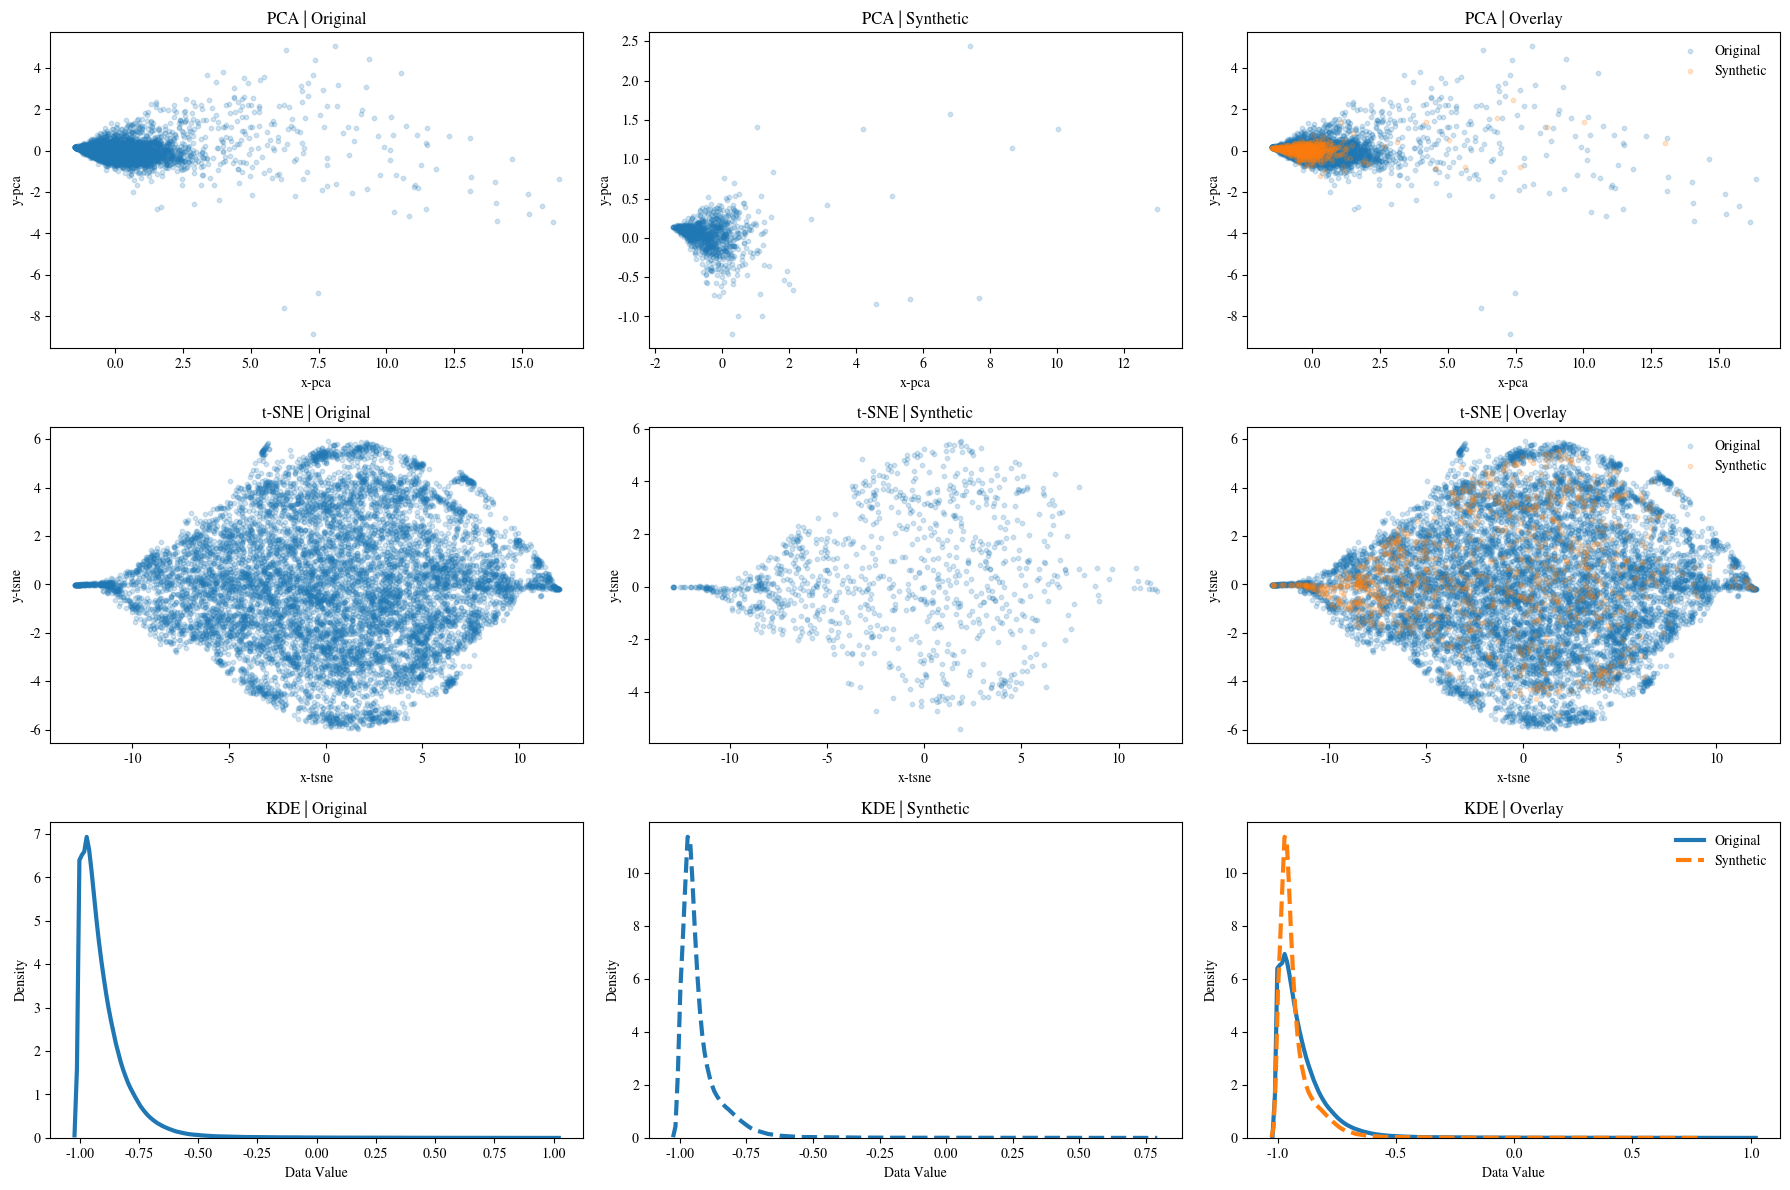

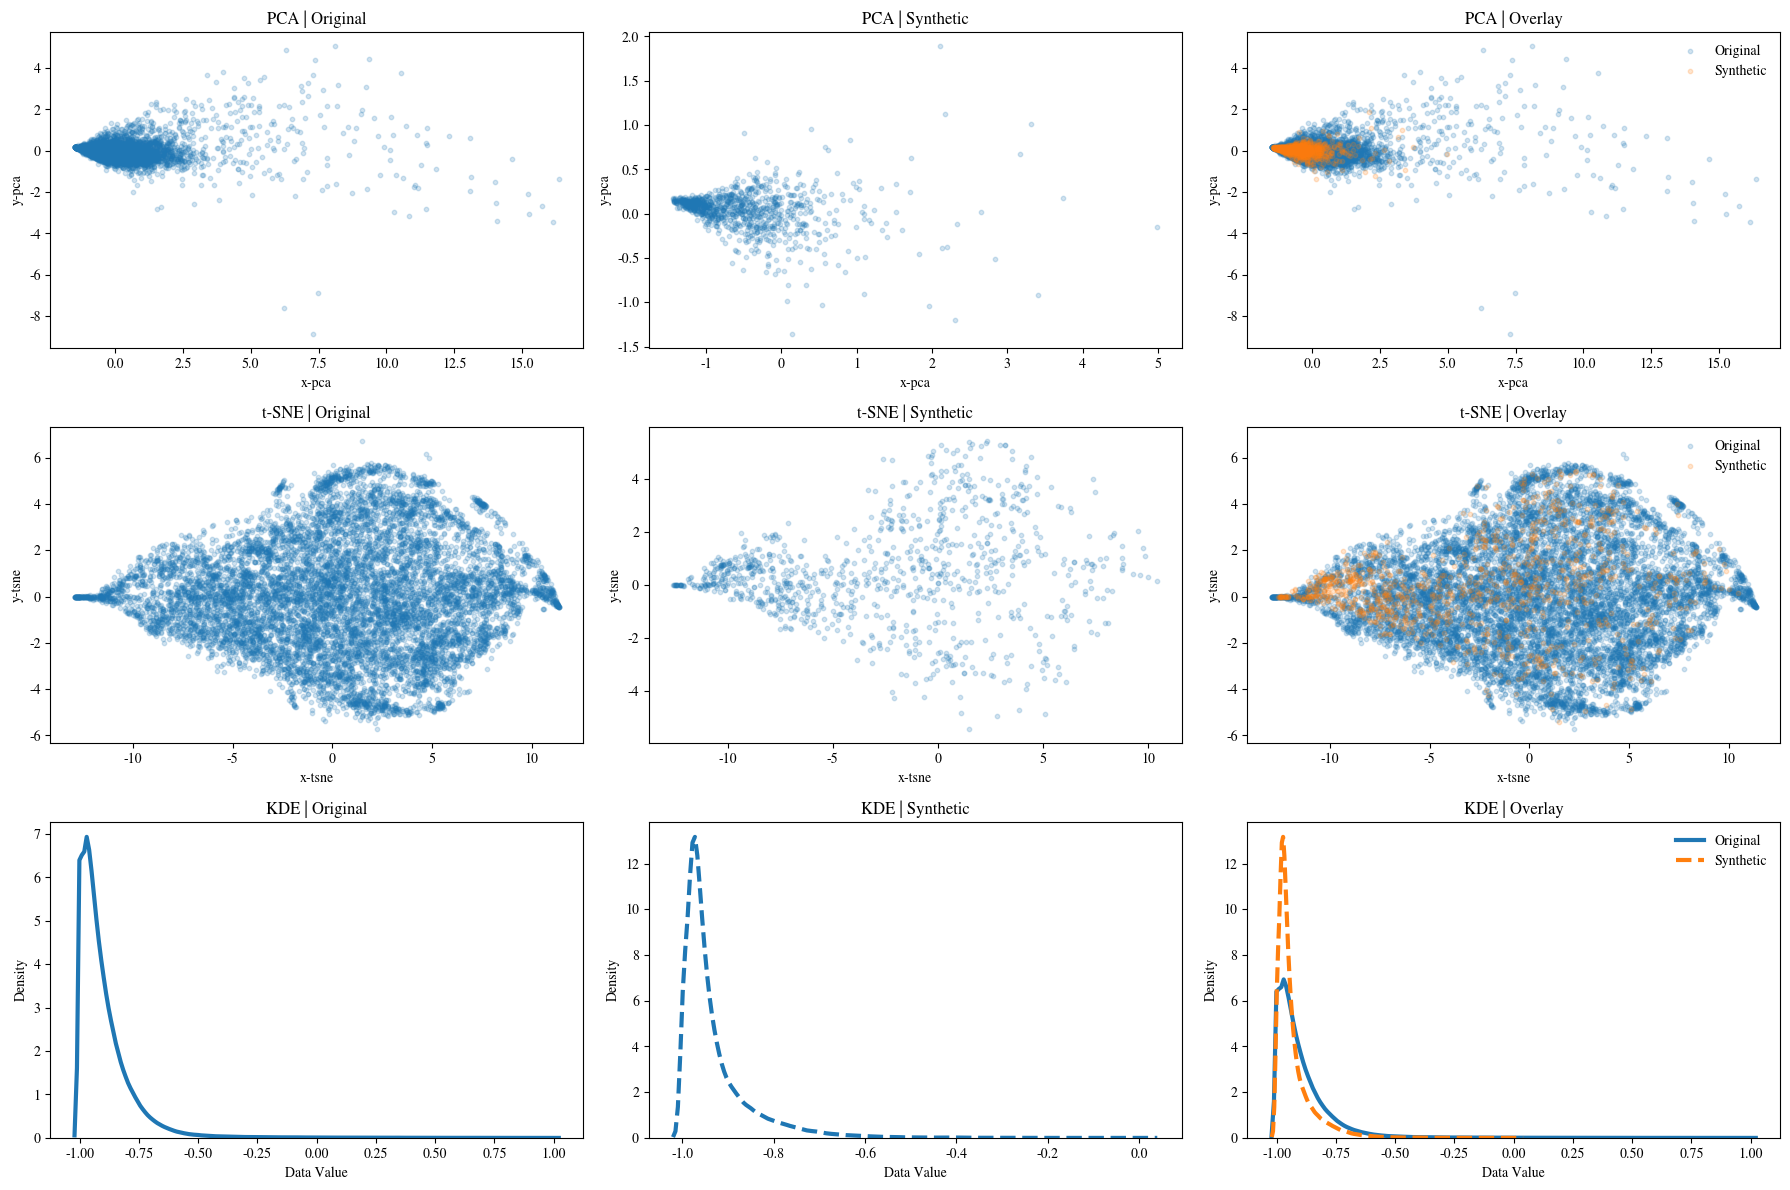

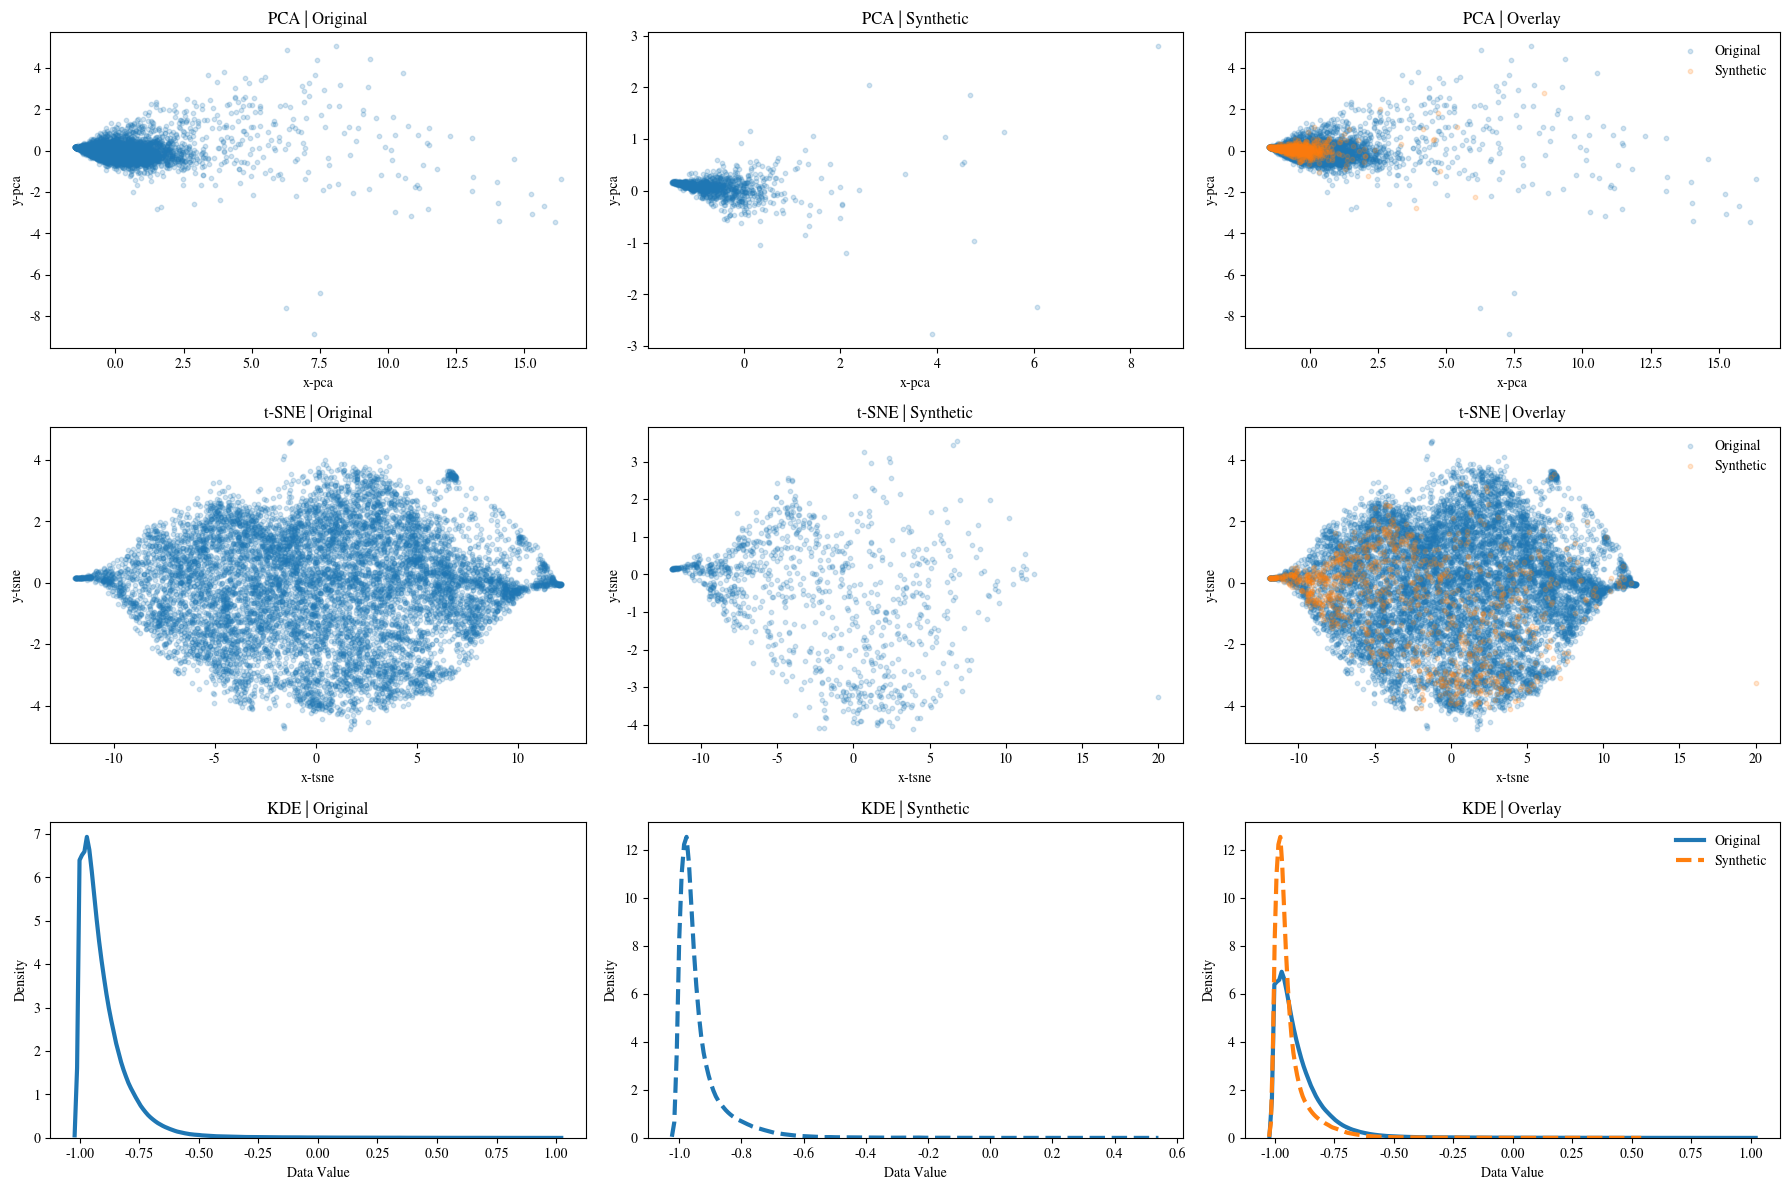

In [4]:
visualization_distribution(ori1, gen11)
visualization_distribution(ori2, gen21)
visualization_distribution(ori3, gen31)

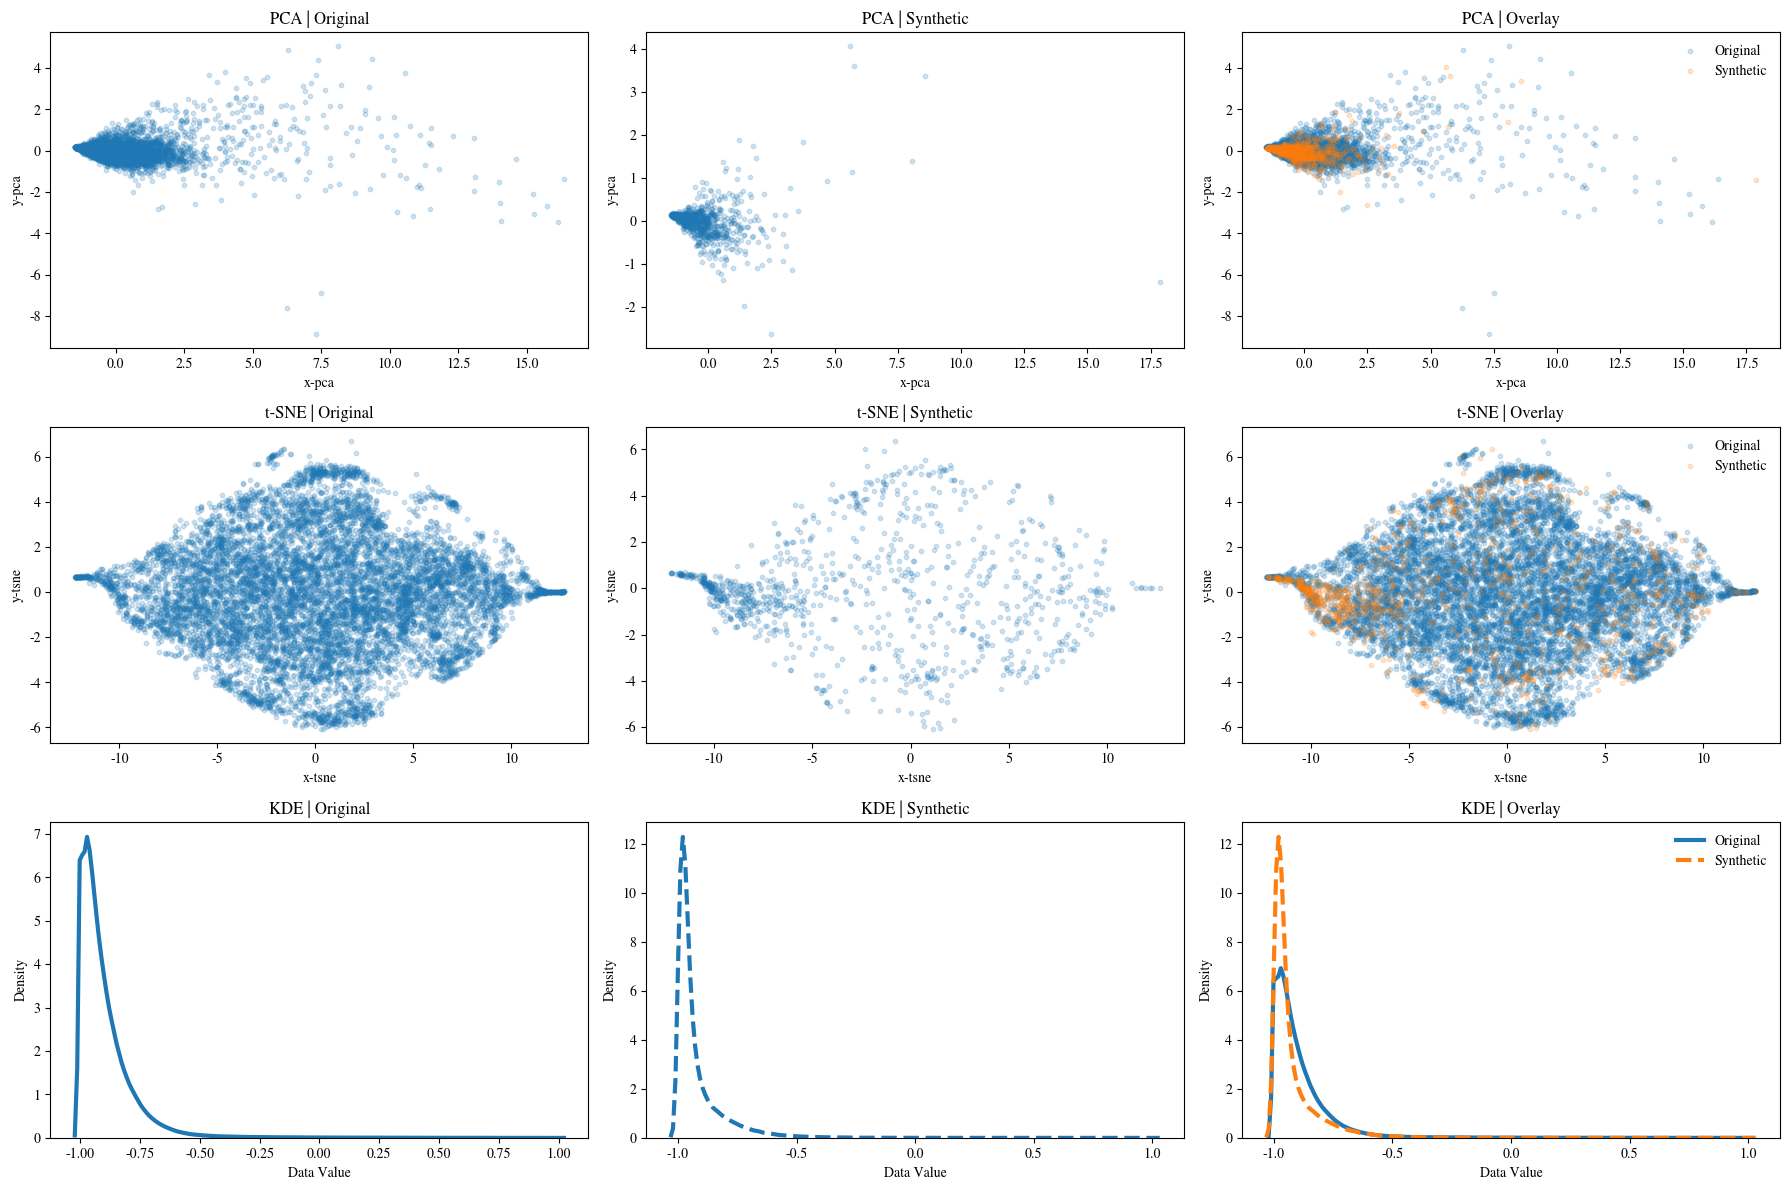

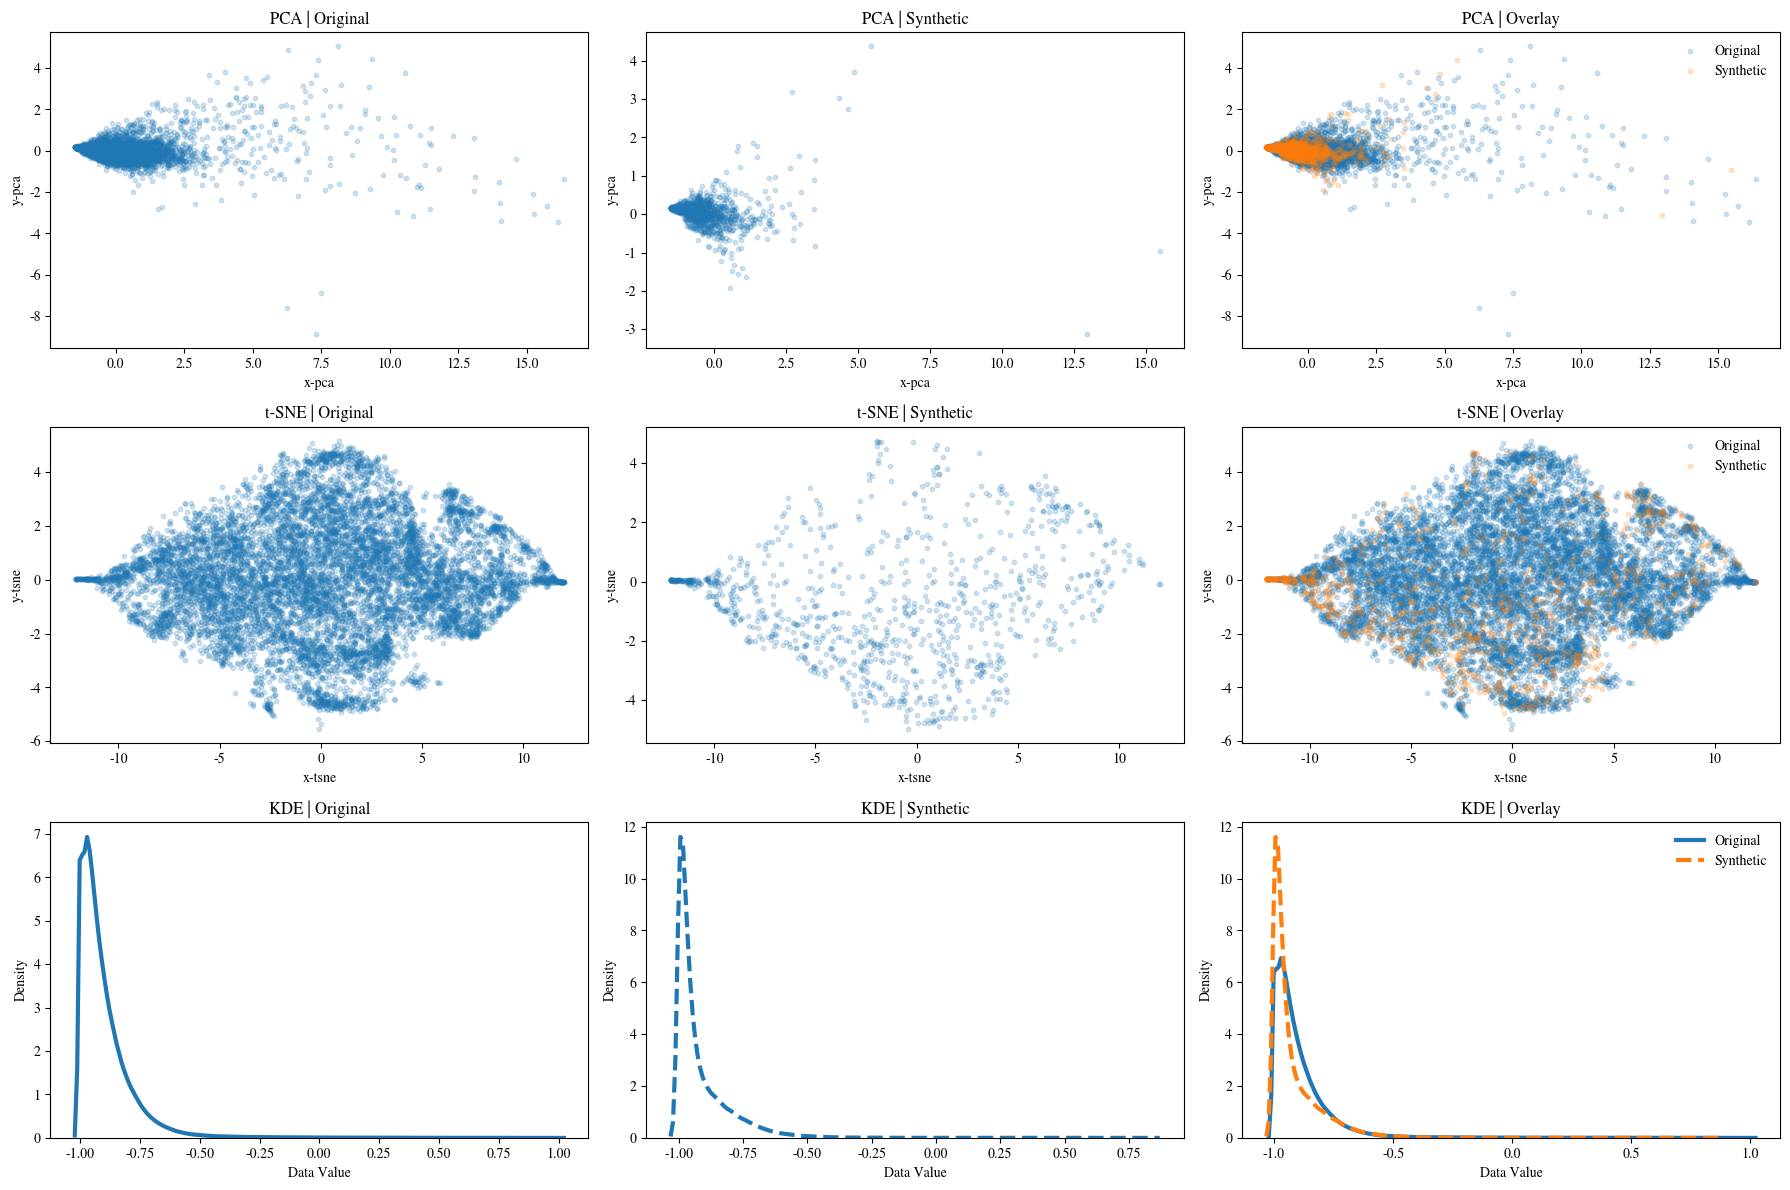

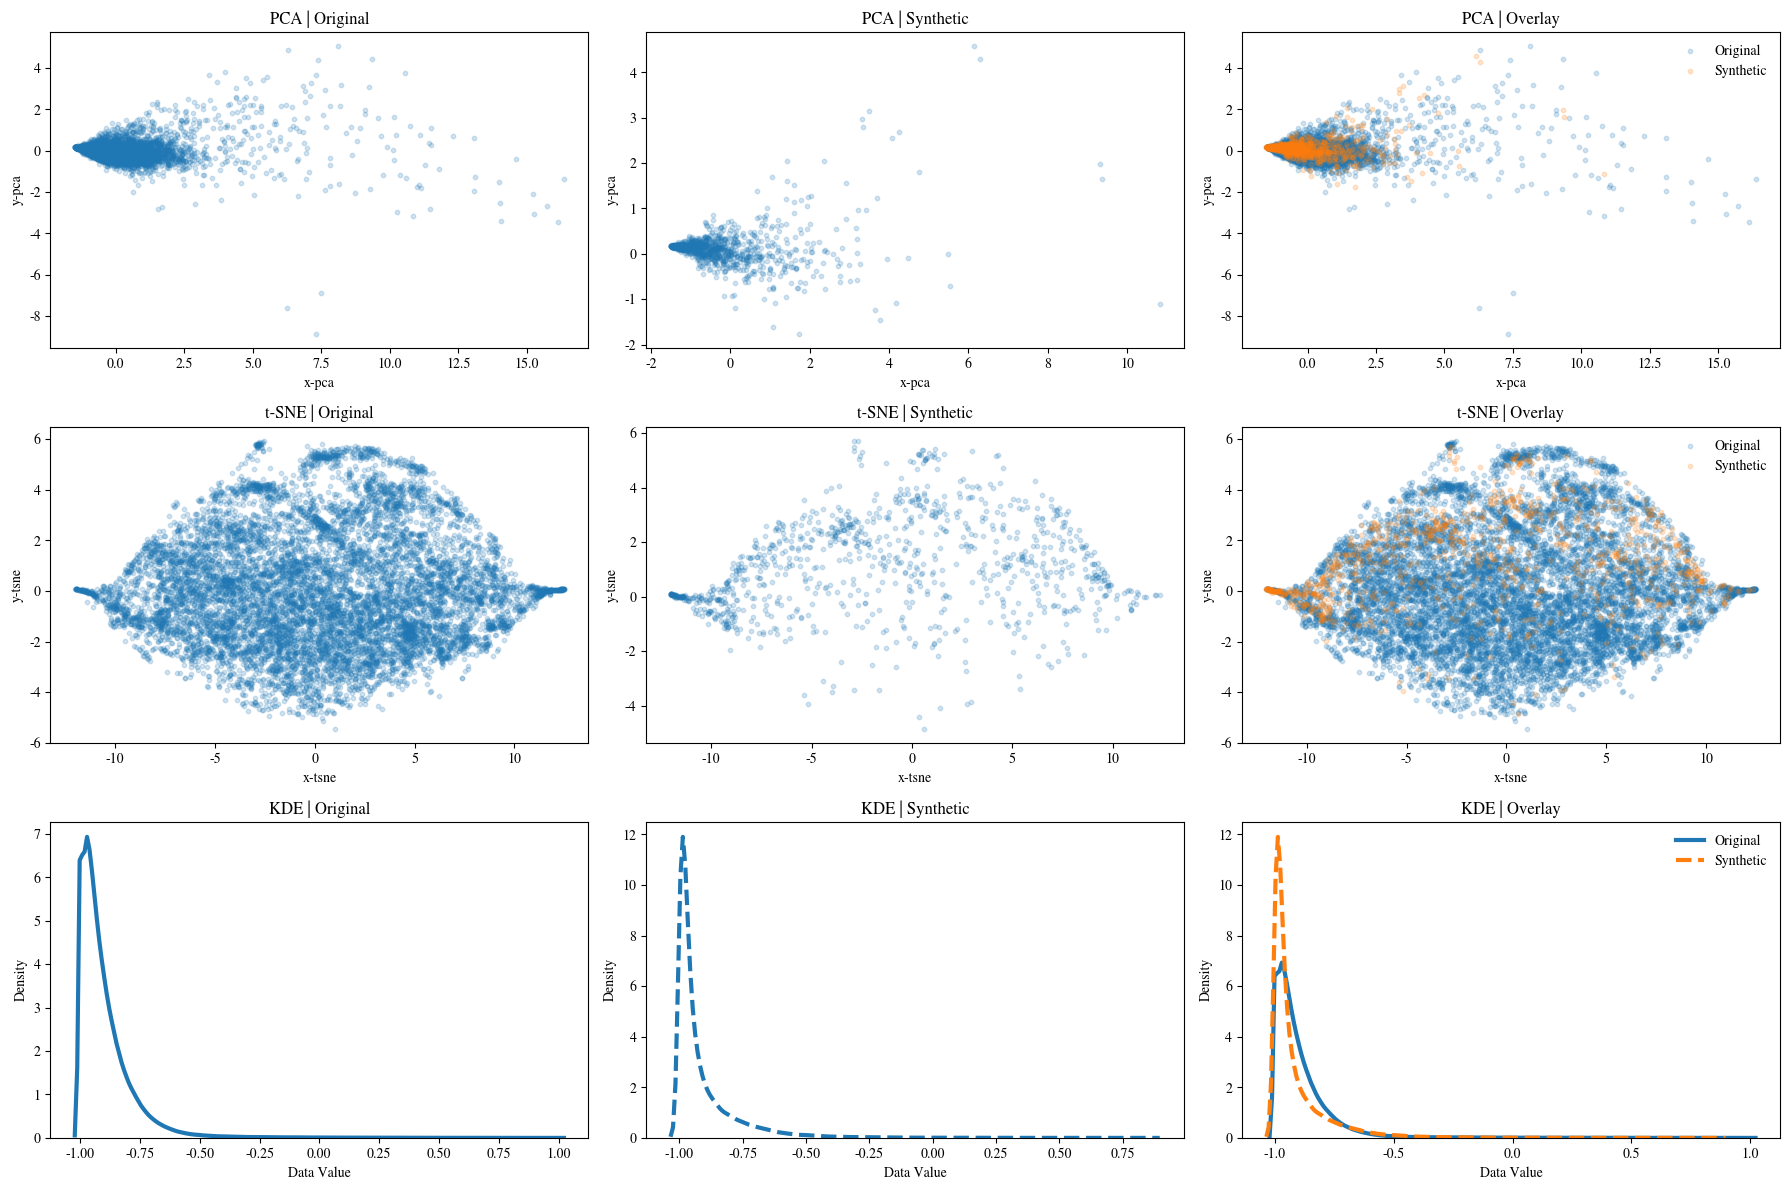

In [5]:
visualization_distribution(ori1, gen12)
visualization_distribution(ori2, gen22)
visualization_distribution(ori3, gen32)

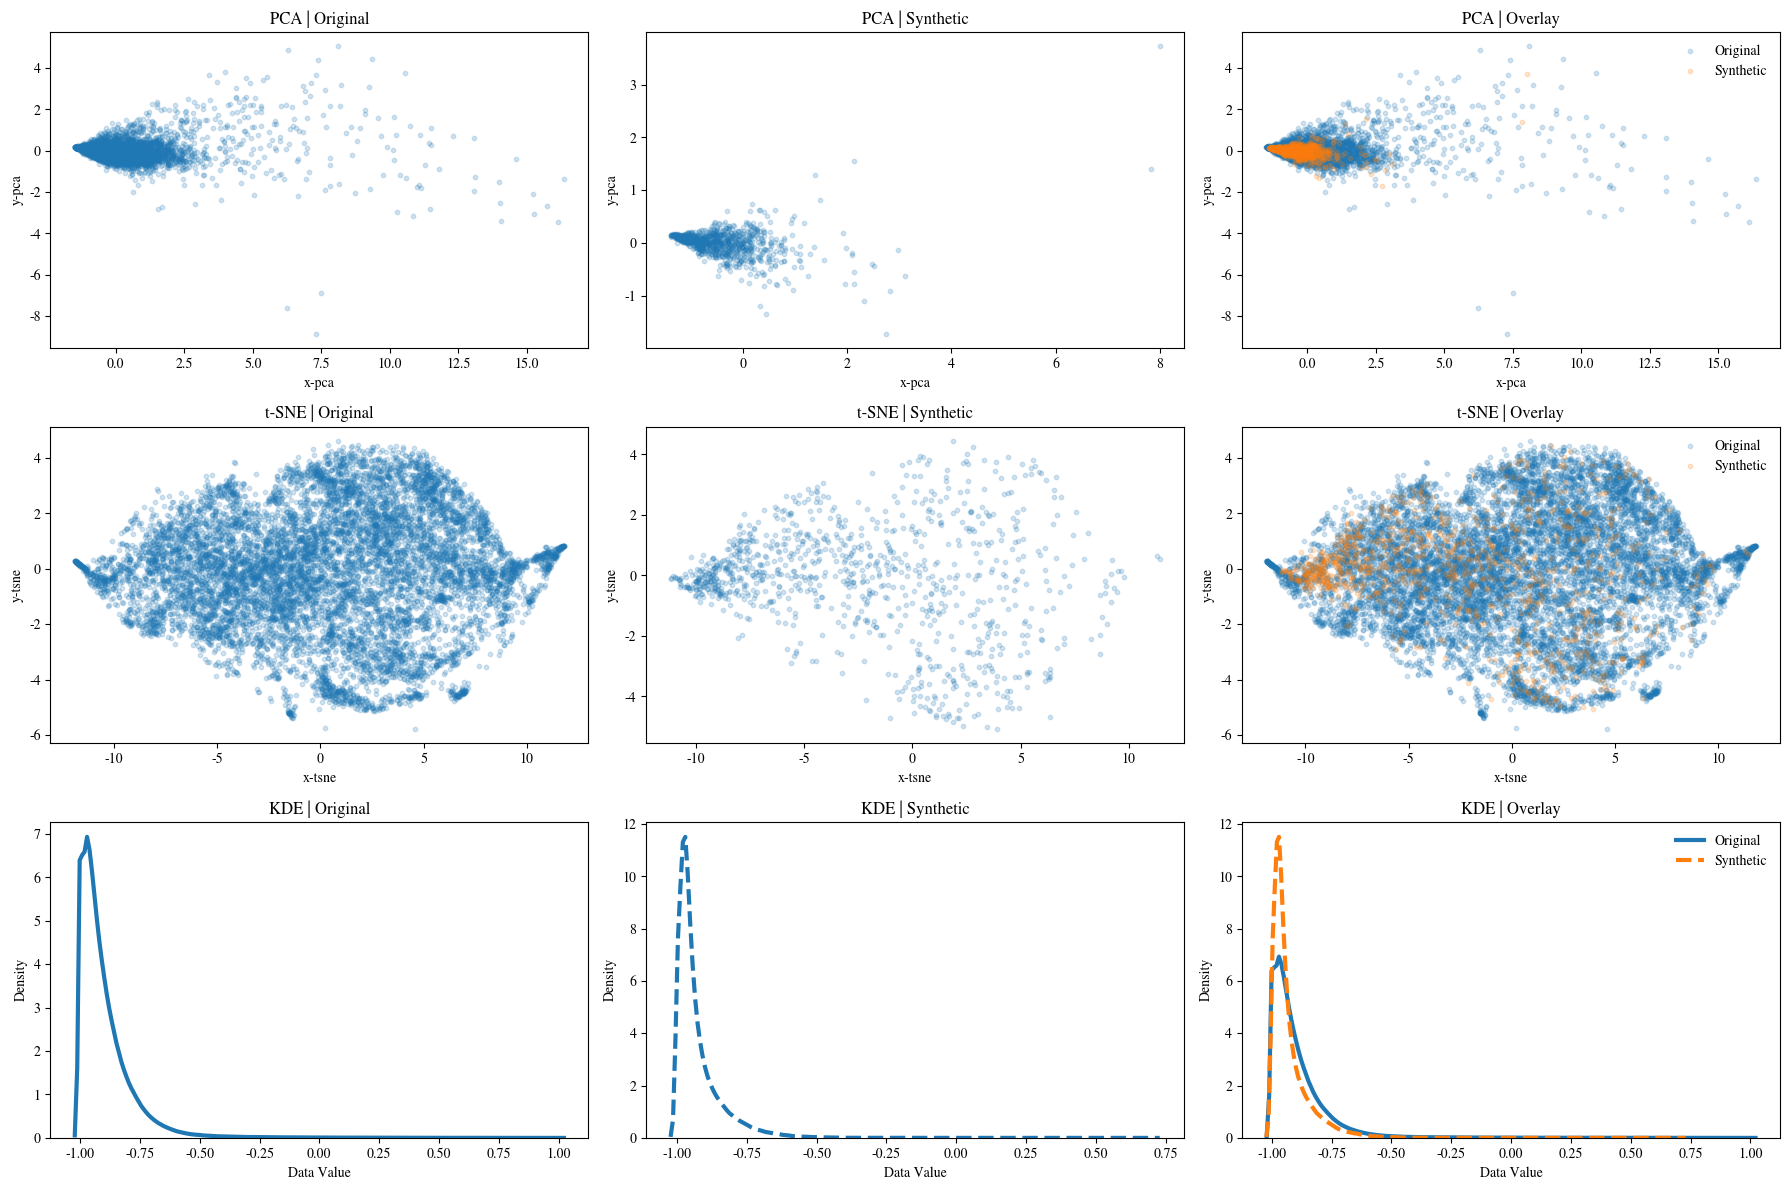

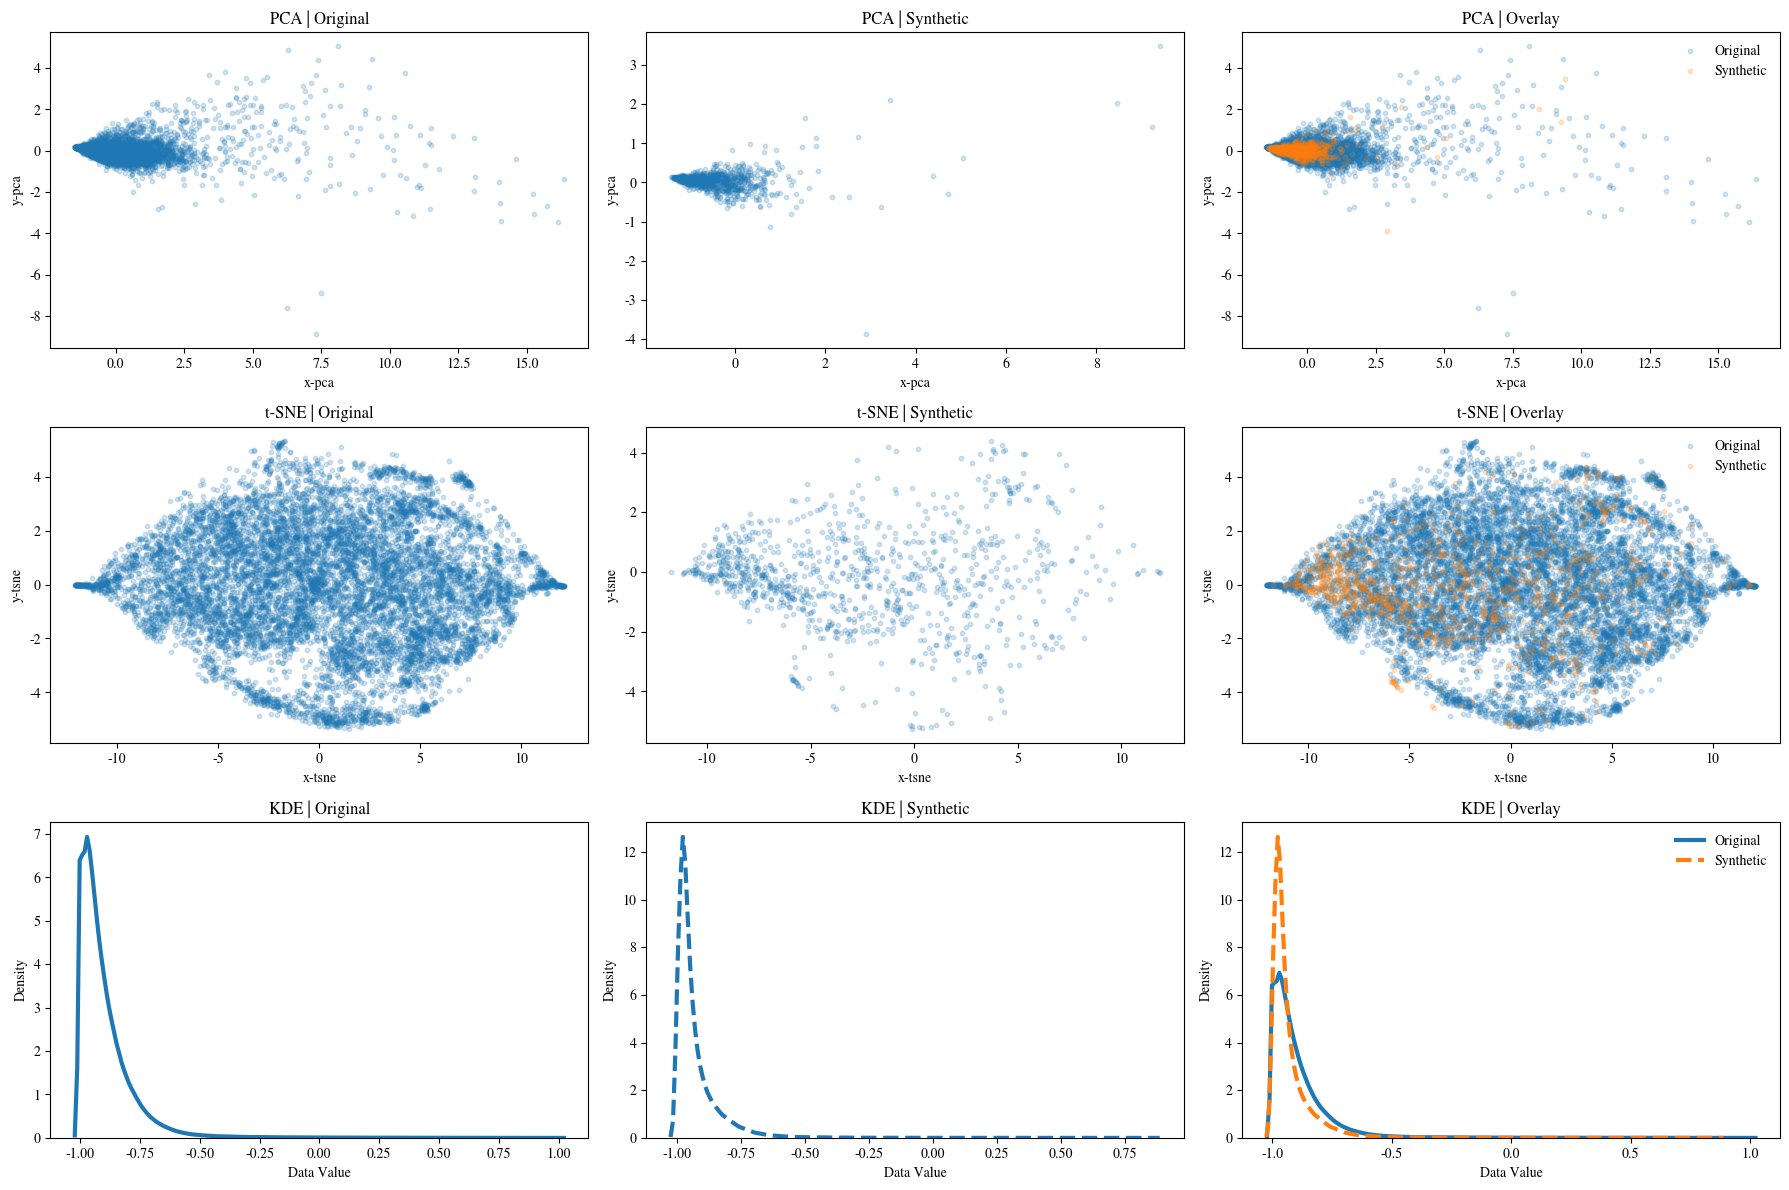

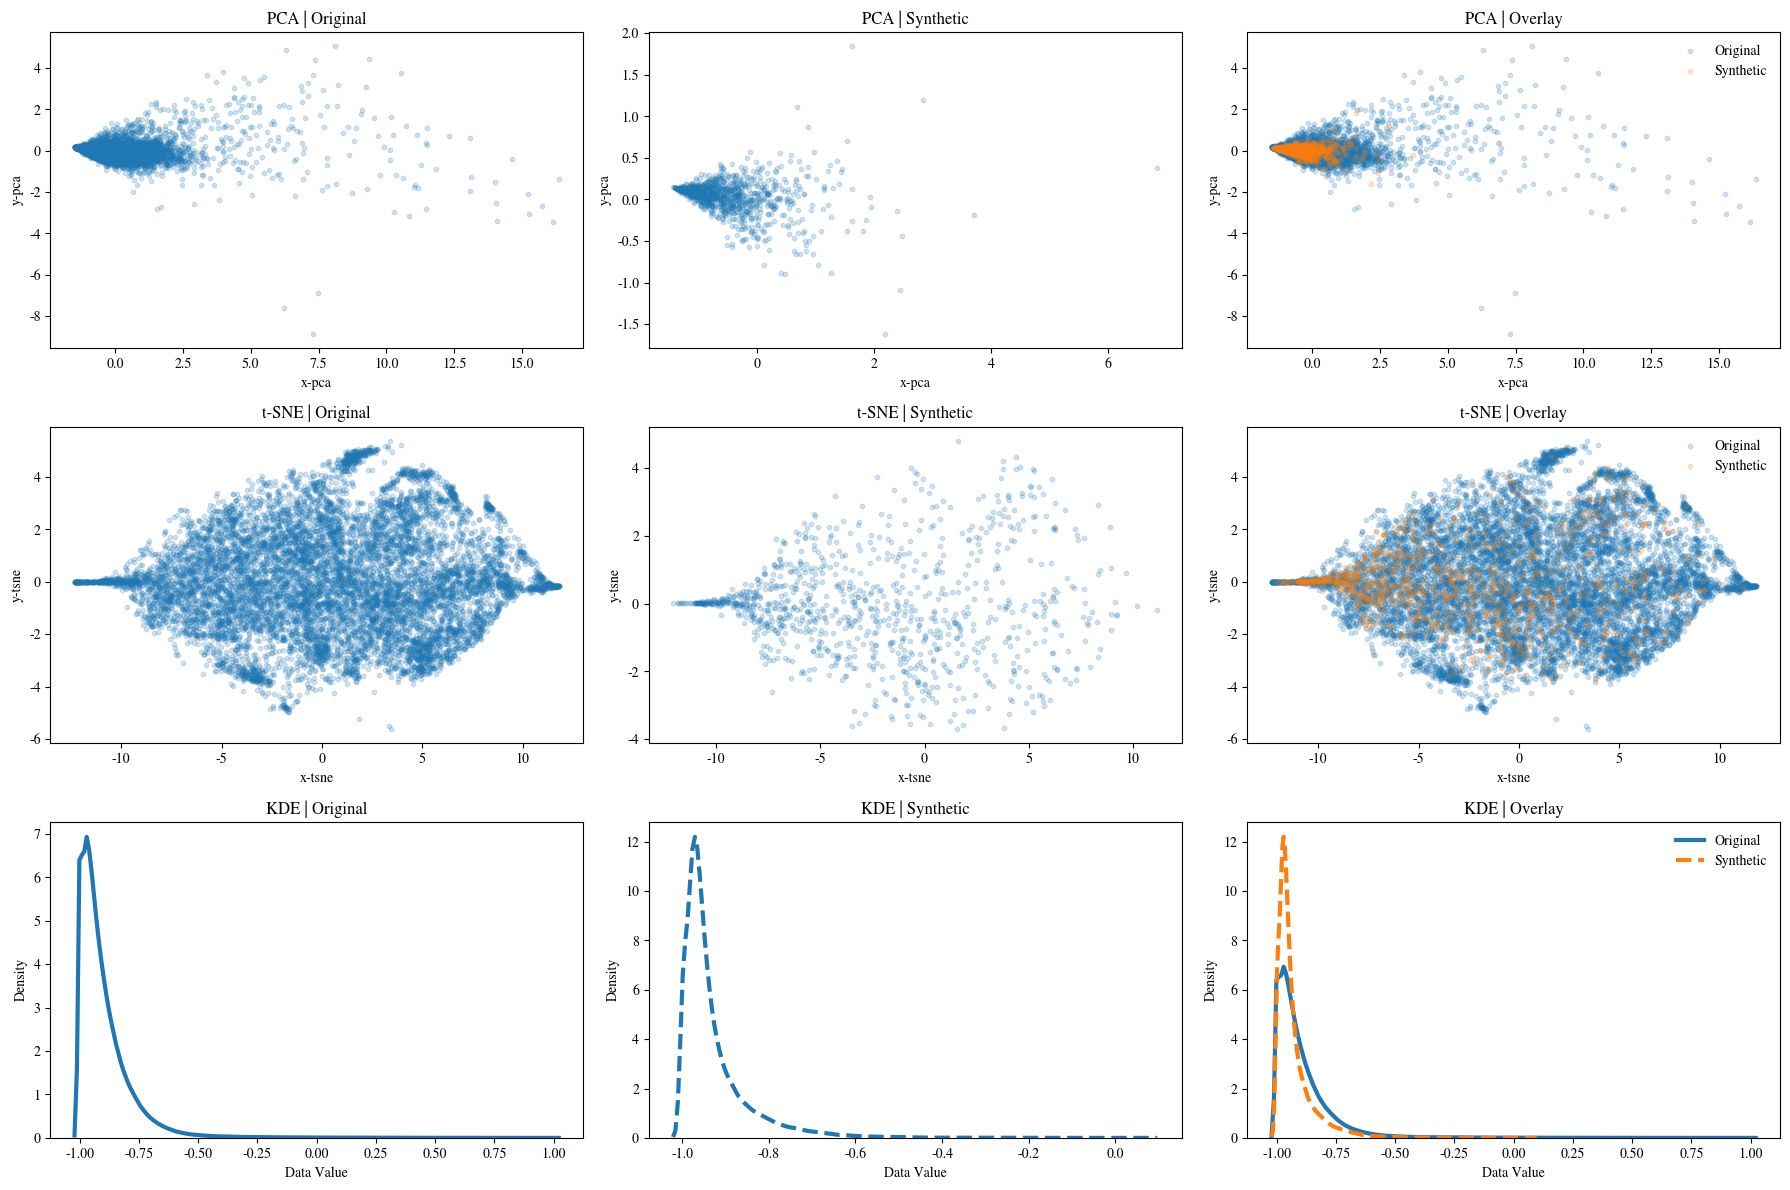

In [6]:
visualization_distribution(ori1, gen13)
visualization_distribution(ori2, gen23)
visualization_distribution(ori3, gen33)

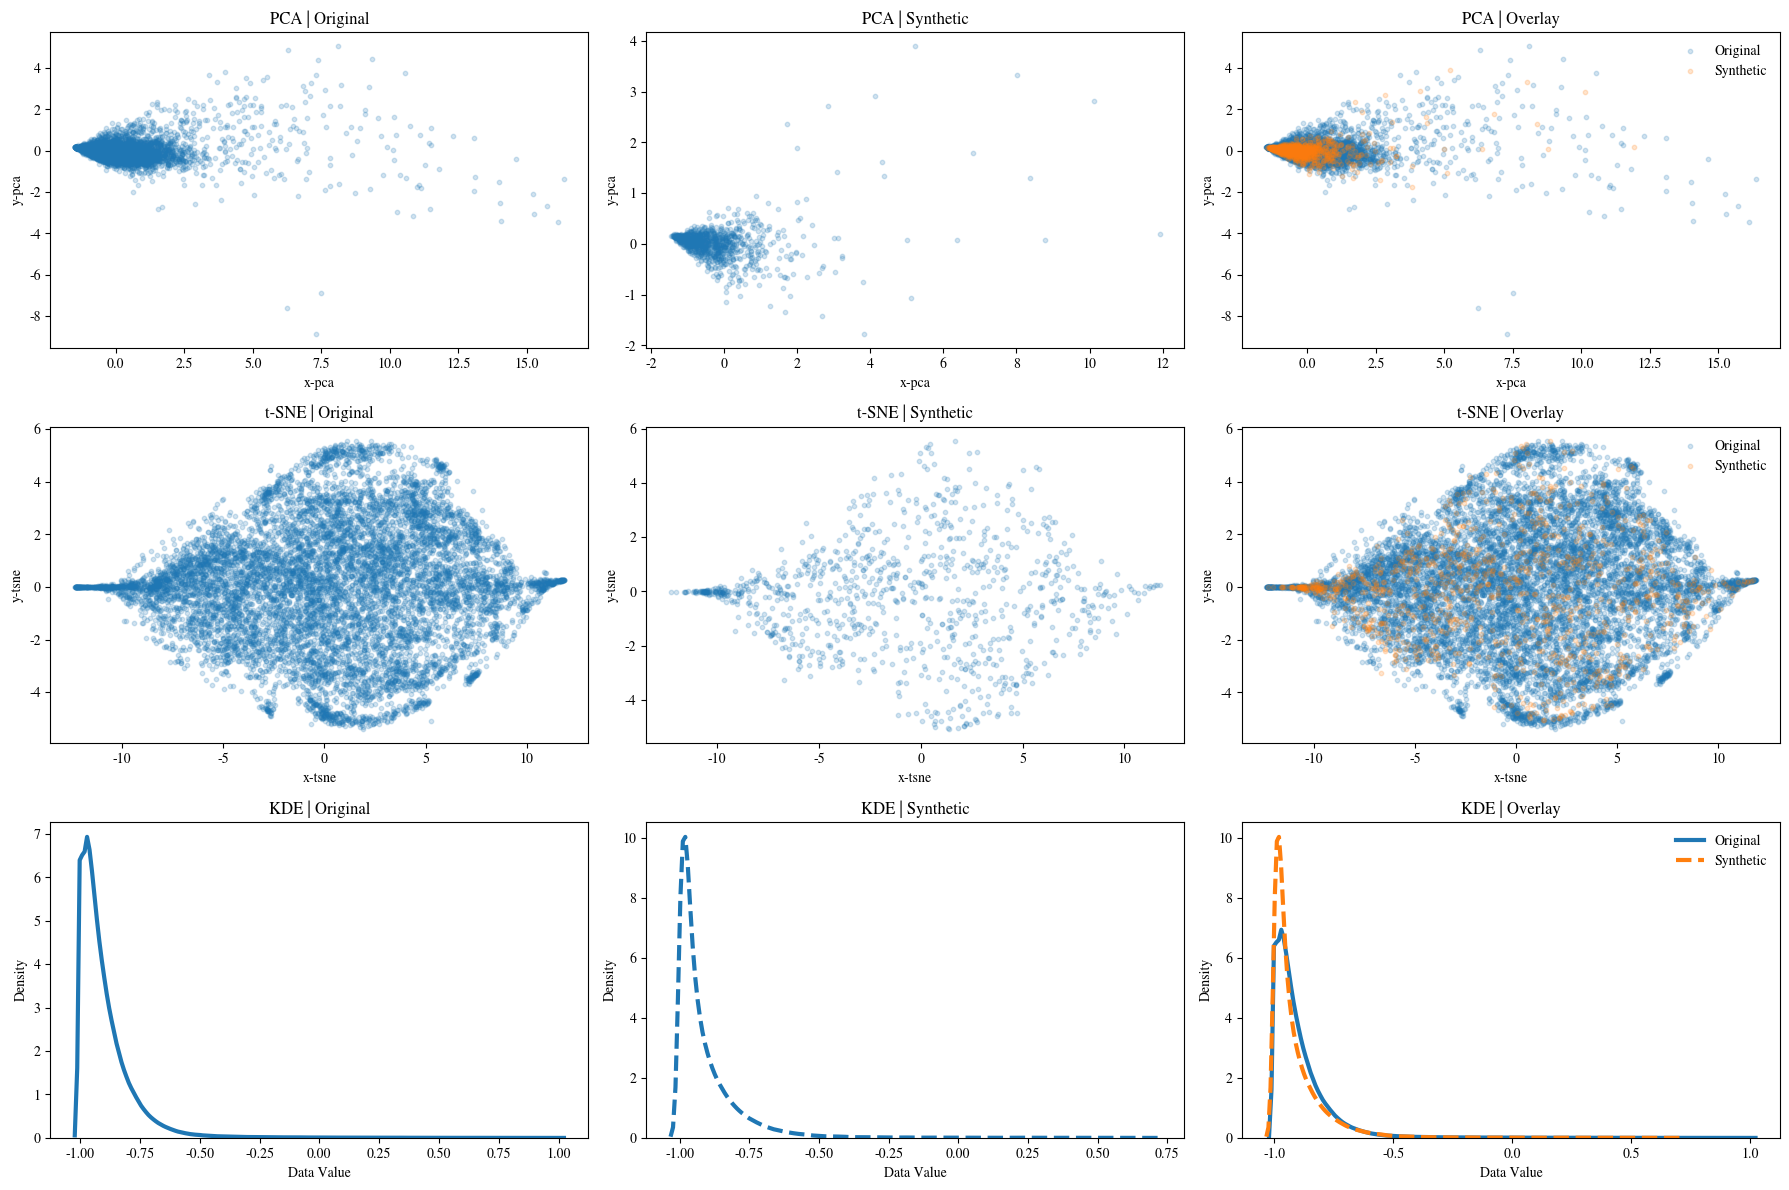

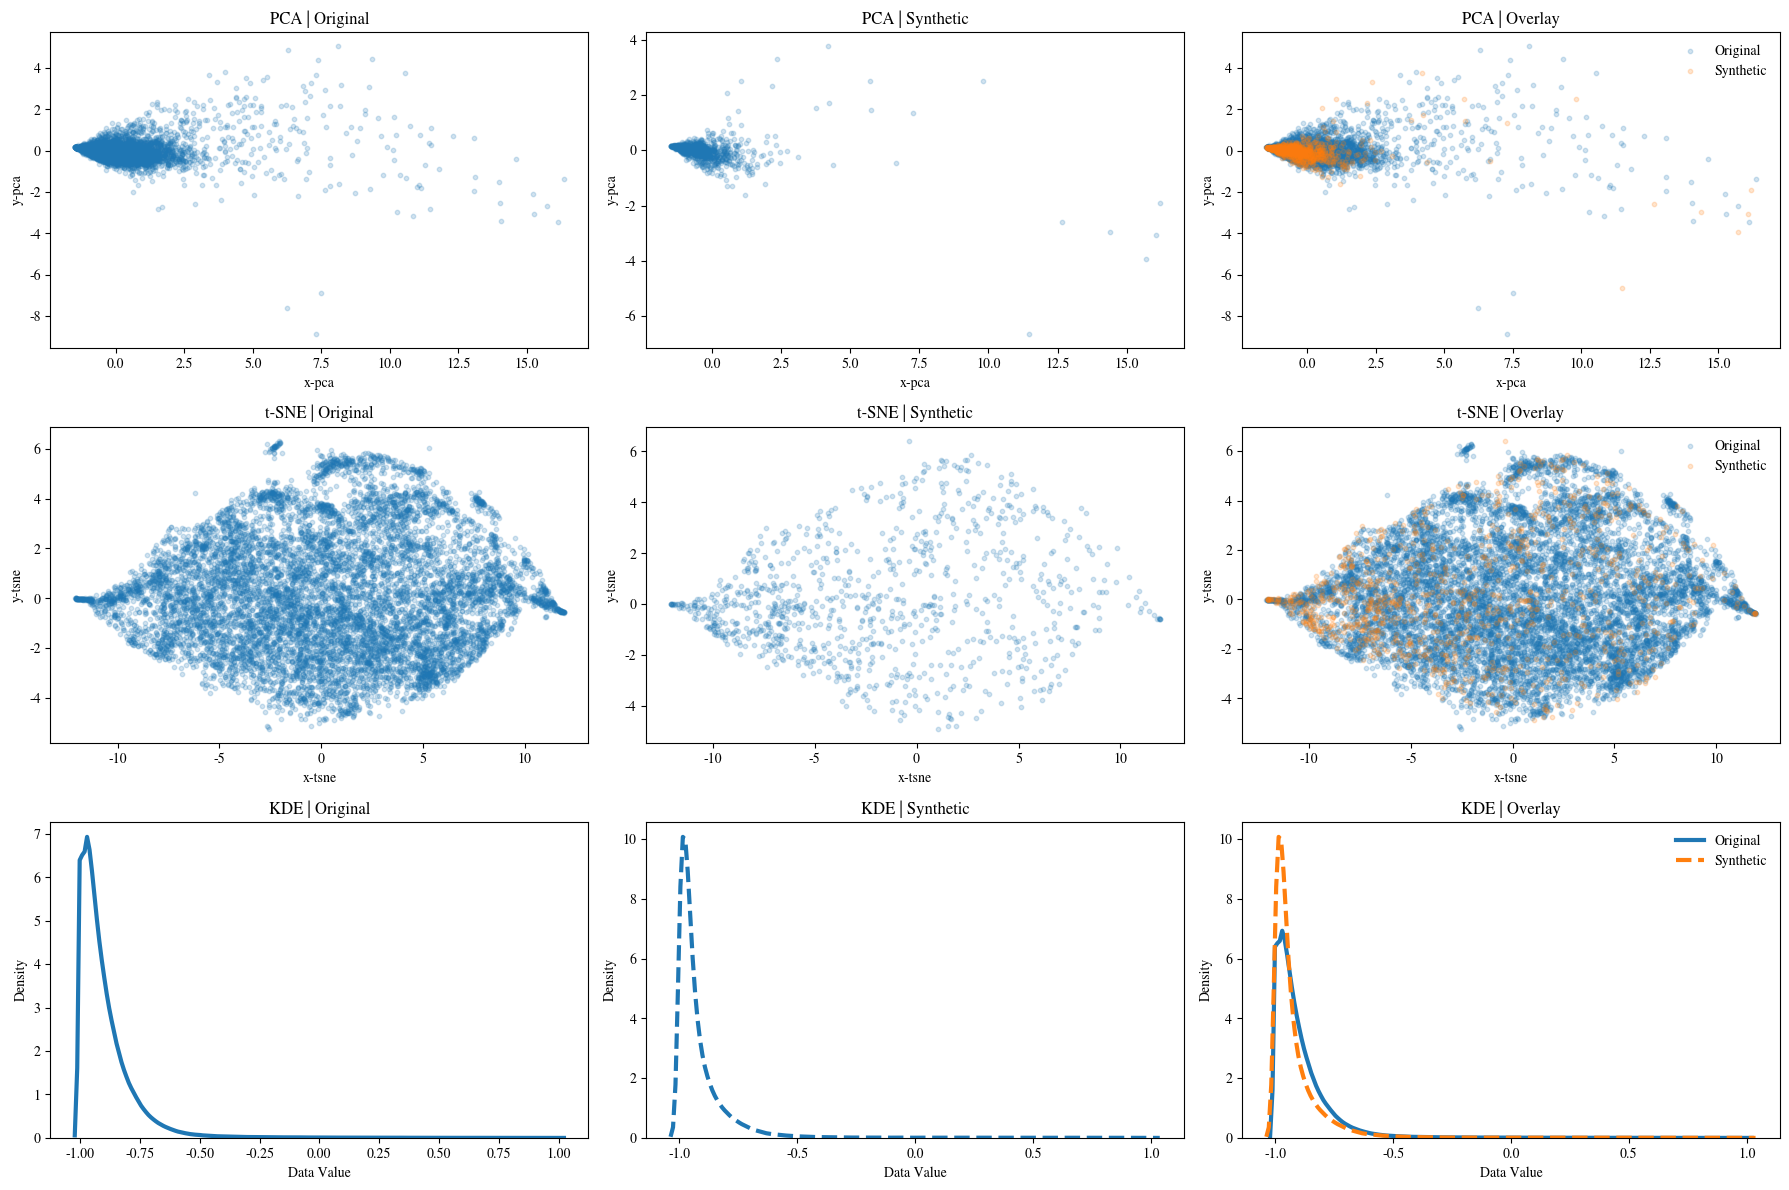

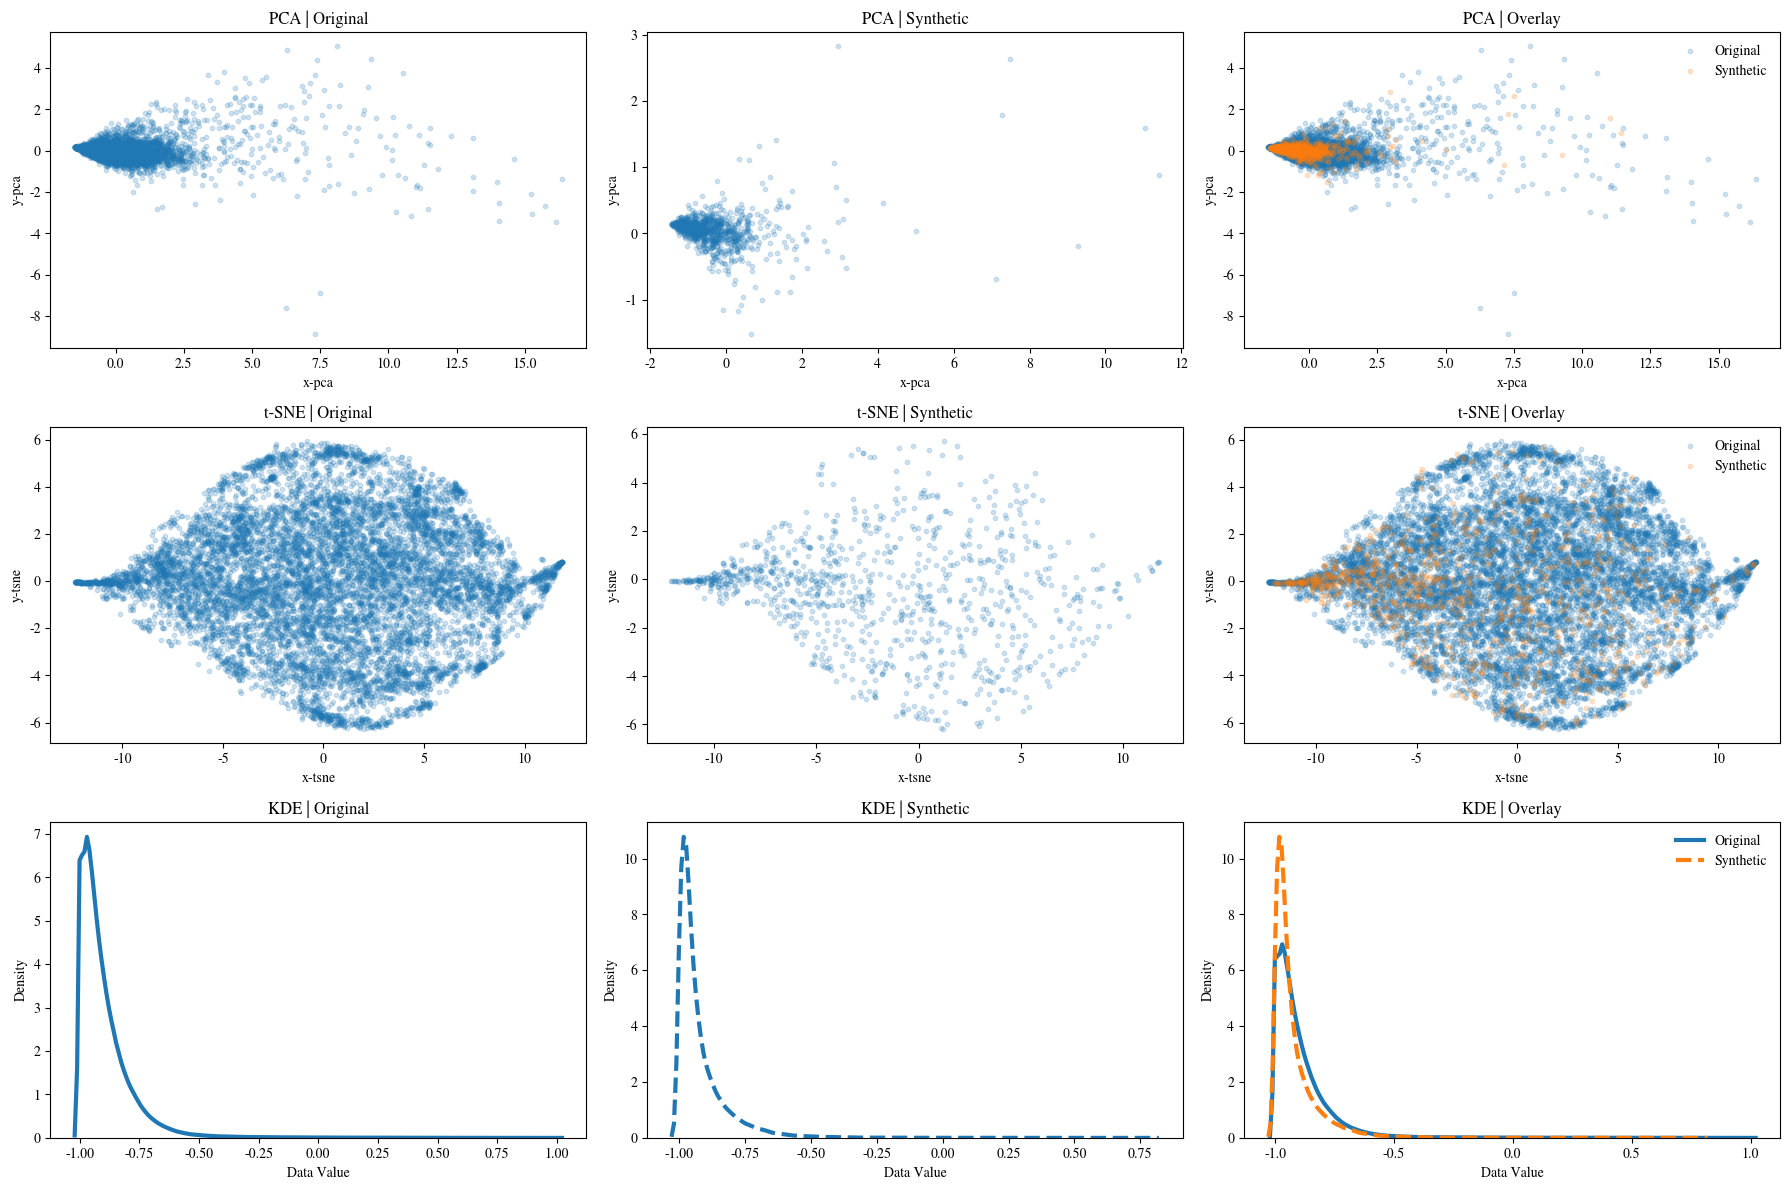

In [7]:
visualization_distribution(ori1, gen14)
visualization_distribution(ori2, gen24)
visualization_distribution(ori3, gen34)